In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [3]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

In [4]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [5]:
df.columns.tolist()

['gender',
 'age',
 'hypertension',
 'heart_disease',
 'smoking_history',
 'bmi',
 'HbA1c_level',
 'blood_glucose_level',
 'diabetes']

In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [7]:
df.isnull().sum()


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [8]:
df["diabetes"].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [10]:
df = df.drop_duplicates()
df = df.dropna()

In [11]:
df.shape

(96146, 9)

In [13]:
df.isnull().sum().sum()

np.int64(0)

In [17]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

print("Input and output created successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Input and output created successfully!
X shape: (96146, 8)
y shape: (96146,)


In [18]:
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Text converted into numbers successfully!")
print(X.head())

Text converted into numbers successfully!
    age  hypertension  heart_disease    bmi  HbA1c_level  blood_glucose_level  \
0  80.0             0              1  25.19          6.6                  140   
1  54.0             0              0  27.32          6.6                   80   
2  28.0             0              0  27.32          5.7                  158   
3  36.0             0              0  23.45          5.0                  155   
4  76.0             1              1  20.14          4.8                  155   

   gender_Male  gender_Other  smoking_history_current  smoking_history_ever  \
0            0             0                        0                     0   
1            0             0                        0                     0   
2            1             0                        0                     0   
3            0             0                        1                     0   
4            1             0                        1                     0 

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and testing data created successfully!")

Training and testing data created successfully!


In [21]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

Decision Tree Accuracy: 82.79 %

Confusion Matrix:
[[14312  3222]
 [   87  1609]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90     17534
           1       0.33      0.95      0.49      1696

    accuracy                           0.83     19230
   macro avg       0.66      0.88      0.69     19230
weighted avg       0.94      0.83      0.86     19230



In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data scaling completed successfully!")

Data scaling completed successfully!


In [26]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

print("KNN Accuracy:",
      round(accuracy_score(y_test, knn_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_pred))

print("\nClassification Report:")
print(classification_report(y_test, knn_pred, zero_division=0))

KNN Accuracy: 95.91 %

Confusion Matrix:
[[17399   135]
 [  651  1045]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98     17534
           1       0.89      0.62      0.73      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.80      0.85     19230
weighted avg       0.96      0.96      0.96     19230



In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

knn_model.fit(X_train_scaled, y_train)

X_test_sample = X_test_scaled[:3000]
y_test_sample = y_test.iloc[:3000]

knn_pred = knn_model.predict(X_test_sample)

print("KNN Accuracy:",
      round(accuracy_score(y_test_sample, knn_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_sample, knn_pred))

print("\nClassification Report:")
print(classification_report(y_test_sample, knn_pred, zero_division=0))

KNN Accuracy: 96.7 %

Confusion Matrix:
[[2745   15]
 [  84  156]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      2760
           1       0.91      0.65      0.76       240

    accuracy                           0.97      3000
   macro avg       0.94      0.82      0.87      3000
weighted avg       0.97      0.97      0.96      3000



In [28]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

Random Forest Accuracy: 90.21 %

Confusion Matrix:
[[15830  1704]
 [  178  1518]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     17534
           1       0.47      0.90      0.62      1696

    accuracy                           0.90     19230
   macro avg       0.73      0.90      0.78     19230
weighted avg       0.94      0.90      0.92     19230



In [30]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

X_test_sample = X_test_scaled[:3000]
y_test_sample = y_test.iloc[:3000]


knn_pred = knn_model.predict(X_test_sample)


print("KNN Accuracy:",
      round(accuracy_score(y_test_sample, knn_pred) * 100, 2), "%")


print("\nConfusion Matrix:")
print(confusion_matrix(y_test_sample, knn_pred))


print("\nClassification Report:")
print(classification_report(
    y_test_sample, knn_pred, zero_division=0
))

KNN Accuracy: 96.7 %

Confusion Matrix:
[[2745   15]
 [  84  156]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      2760
           1       0.91      0.65      0.76       240

    accuracy                           0.97      3000
   macro avg       0.94      0.82      0.87      3000
weighted avg       0.97      0.97      0.96      3000



       Algorithm  Accuracy (%)
0  Decision Tree         83.10
1            KNN         96.70
2  Random Forest         90.63


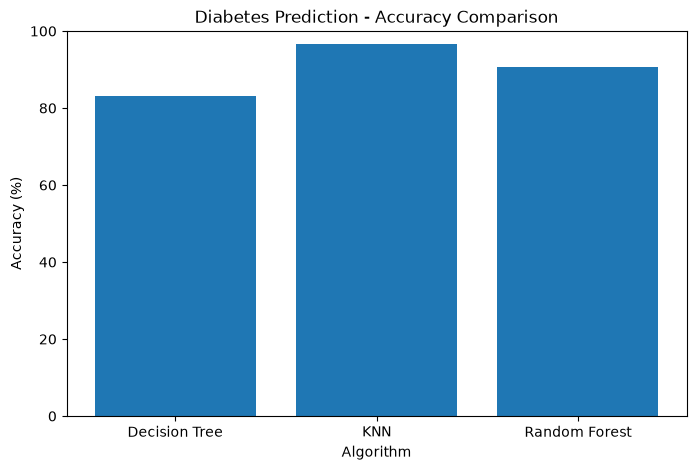

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score


X_test_sample = X_test.iloc[:3000]
X_test_scaled_sample = X_test_scaled[:3000]
y_test_sample = y_test.iloc[:3000]


dt_pred_sample = dt_model.predict(X_test_sample)
knn_pred = knn_model.predict(X_test_scaled_sample)
rf_pred_sample = rf_model.predict(X_test_sample)


results = pd.DataFrame({
    "Algorithm": [
        "Decision Tree",
        "KNN",
        "Random Forest"
    ],
    "Accuracy (%)": [
        round(accuracy_score(y_test_sample, dt_pred_sample) * 100, 2),
        round(accuracy_score(y_test_sample, knn_pred) * 100, 2),
        round(accuracy_score(y_test_sample, rf_pred_sample) * 100, 2)
    ]
})

print(results)

# Display graph
plt.figure(figsize=(8, 5))
plt.bar(results["Algorithm"], results["Accuracy (%)"])
plt.title("Diabetes Prediction - Accuracy Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

In [34]:
new_person = pd.DataFrame([{
    "gender": "Female",
    "age": 45,
    "hypertension": 0,
    "heart_disease": 0,
    "smoking_history": "never",
    "bmi": 27.5,
    "HbA1c_level": 5.8,
    "blood_glucose_level": 120
}])

new_person = pd.get_dummies(
    new_person,
    drop_first=True,
    dtype=int
)

new_person = new_person.reindex(
    columns=X.columns,
    fill_value=0
)

prediction = rf_model.predict(new_person)[0]

print("Random Forest Prediction:", prediction)

if prediction == 1:
    print("Predicted class: Diabetes-positive")
else:
    print("Predicted class: Diabetes-negative")

Random Forest Prediction: 0
Predicted class: Diabetes-negative
